# Síndrome metabólico silencioso e hiperuricemia en adultos jóvenes (NHANES 2013–2014)

**Autor:** Erick Israel Rodríguez Zavala · Maestría en Inteligencia Artificial, TecNM campus Aguascalientes
**Materia:** Visualización de datos · Proyecto integrador (Avances 1 a 3)

**Pregunta del proyecto.** ¿Qué tan frecuente es que un adulto joven (18 a 35 años) tenga alterados los componentes del síndrome metabólico, o el ácido úrico, sin haber recibido un diagnóstico?

**Fuente de datos.** National Health and Nutrition Examination Survey (NHANES) 2013–2014, Centers for Disease Control and Prevention / National Center for Health Statistics.
- Página del ciclo: https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?BeginYear=2013
- Patrón de descarga de cada archivo: `https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2013/DataFiles/<ARCHIVO>.xpt`
- **Fecha de extracción:** 1 de octubre de 2026.

Este cuaderno sigue el flujo **carga → limpieza → EDA → visualizaciones finales**. No contiene pasos manuales: cada celda llama a los scripts numerados de `codigo/`, que son la única fuente de la lógica (así el cuaderno y los scripts nunca se contradicen).

| Paso | Script | Entrada | Salida |
|---|---|---|---|
| 0 | `00_descargar_nhanes.py` | sitio del CDC | `datos/crudos/*.xpt` (solo los que falten) |
| 1 | `01_preparar_datos.py` | 17 archivos `.xpt` | `datos/procesados/nhanes_2013_2014_jovenes_clean.csv` |
| 2 | `02_calculos_eda.py` | tabla limpia | `datos/resumen/eda_no_lo_sabe.csv` |
| 3 | `03_actividad_por_hora.py` | tabla limpia + `PAXHR_H.xpt` | `datos/resumen/eda_actividad_por_hora.csv` |
| 4 | `04_graficas_avance2.py` | tabla limpia + resúmenes | `figuras/avance2/fig1…fig5.png` |
| 5 | `05_estatica_avance3.py` | `eda_no_lo_sabe.csv` | `figuras/avance3/estatica_no_lo_sabe.png` |
| 6 | `06_interactiva_avance3.py` | tabla limpia | `figuras/avance3/interactiva_cintura_acido_urico.html` |
| 7 | `07_datos_tableau.py` | tabla limpia | `datos/tableau/nhanes_tableau.xlsx` |
| 8 | `08_dashboard_final.py` | tabla limpia | `figuras/avance4/dashboard_final.html` |

In [1]:
import sys, os
from pathlib import Path
RAIZ = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ / 'codigo'))
from config import CRUDOS, CSV_LIMPIO, RESUMEN, TABLEAU, FIG_A2, FIG_A3
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
import runpy
correr = lambda n: runpy.run_path(str(RAIZ / 'codigo' / n), run_name='__main__')   # ejecuta un script del pipeline
print('Carpeta del proyecto:', RAIZ.name)

Carpeta del proyecto: nhanes-sindrome-metabolico-jovenes


## 1. Carga de datos

NHANES publica cada tema en un archivo SAS de transporte (`.xpt`). Todos comparten la llave **SEQN** (identificador anónimo del participante), que es la que permite unirlos en una sola tabla.

| Archivo | Contenido | Variables que se usan |
|---|---|---|
| DEMO_H | Demografía | sexo, edad, etnia, ingreso, ponderador |
| BIOPRO_H | Bioquímica estándar | ácido úrico, glucosa sin ayuno, triglicéridos |
| GLU_H | Glucosa en ayunas (submuestra matutina) | glucosa en ayunas |
| GHB_H | Hemoglobina glucosilada | HbA1c |
| HDL_H / TCHOL_H | Colesterol HDL / total | HDL, colesterol total |
| BMX_H | Medidas corporales | IMC, cintura |
| BPX_H | Presión arterial (examen) | 3 lecturas sistólicas y diastólicas |
| DIQ_H / BPQ_H / MCQ_H | Cuestionarios de diagnóstico | diabetes, prediabetes, presión, colesterol, gota, sobrepeso |
| HUQ_H / HIQ_H / SLQ_H | Uso de servicios, seguro, sueño | salud autopercibida, médico habitual, seguro, horas de sueño |
| PAXDAY_H / PAXHD_H / PAXHR_H | Acelerómetro de muñeca (día, encabezado, hora) | días válidos, actividad (MIMS), sueño |

Si falta algún archivo, `00_descargar_nhanes.py` lo descarga. `PAXHR_H.xpt` (≈145 MB) excede el límite de GitHub (100 MB por archivo) y por eso no está en el repositorio: se descarga con el paso 0 y solo hace falta para el paso 3.

In [2]:
archivos = sorted(CRUDOS.glob('*.xpt'))
resumen = []
for f in archivos:
    if f.stem == 'PAXHR_H':      # 145 MB: solo se reporta el tamaño
        resumen.append((f.stem, None, None, round(f.stat().st_size / 1e6, 1))); continue
    t = pd.read_sas(f, format='xport')
    resumen.append((f.stem, len(t), t.shape[1], round(f.stat().st_size / 1e6, 1)))
pd.DataFrame(resumen, columns=['archivo', 'filas', 'columnas', 'MB']).astype({'filas': 'Int64', 'columnas': 'Int64'})

,archivo,filas,columnas,MB
0,BIOPRO_H,6979,38,2.1
1,BMX_H,9813,26,2.0
2,BPQ_H,6464,14,0.7
3,BPX_H,9813,23,1.8
4,DEMO_H,10175,47,3.8
5,DIQ_H,9770,54,4.2
6,GHB_H,6979,2,0.1
7,GLU_H,3329,6,0.2
8,HDL_H,8291,3,0.2
9,HIQ_H,10175,17,1.4


## 2. Limpieza y transformación

`01_preparar_datos.py` hace la unión y crea las variables derivadas. Cada decisión lleva en el código una etiqueta que dice de dónde viene: **[GUÍA]** guía clínica publicada, **[NHANES]** libro de códigos, **[CONVENCIÓN]** criterio habitual en la literatura, **[PROPIA]** decisión del proyecto (se declara como limitación).

| Transformación | Regla | Origen |
|---|---|---|
| Unión de tablas | izquierda desde DEMO_H por SEQN | [PROPIA] no perder personas por un dato secundario |
| Población | 18 a 35 años con ácido úrico y HDL medidos | [PROPIA] población de la tesis |
| Día válido de acelerómetro | ≥ 23 h de registro, ≥ 18 h de uso total, ≥ 10 h de uso en vigilia | Troiano et al. (2008) + [PROPIA] |
| Persona con acelerómetro válido | ≥ 4 días válidos | Troiano et al. (2008) |
| Presión arterial | promedio de hasta 3 lecturas; diastólica = 0 se trata como faltante | [PROPIA] / [NHANES] |
| Cintura alterada | ≥ 102 cm hombres, ≥ 88 cm mujeres | Alberti et al. (2009) |
| Triglicéridos altos | ≥ 150 mg/dL | Alberti et al. (2009) |
| HDL bajo | < 40 mg/dL hombres, < 50 mg/dL mujeres | Alberti et al. (2009) |
| Presión elevada | ≥ 130/85 mmHg o tratamiento | Alberti et al. (2009) |
| Glucosa alterada | ayunas ≥ 100 mg/dL; sin ayuno, HbA1c ≥ 5.7 %; o tratamiento | Alberti et al. (2009); ADA (2024) |
| Síndrome metabólico | ≥ 3 de 5 componentes, solo con los 5 evaluables | Alberti et al. (2009) |
| Hiperuricemia | > 7.0 mg/dL hombres, > 5.7 mg/dL mujeres | Chen-Xu et al. (2019) |
| Categoría de IMC | < 25 normal, 25–29.9 sobrepeso, ≥ 30 obesidad | CDC (2024) |
| «No lo sabe» | valor alterado medido y sin diagnóstico médico previo autorreportado | [PROPIA] |
| Gota | la pregunta solo se hace a 20+ años: 18–19 quedan como faltante | [NHANES] |

In [3]:
_ = correr('01_preparar_datos.py')

Personas 18-35 con laboratorios: 1730 | con acelerómetro válido: 1143


In [4]:
d = pd.read_csv(CSV_LIMPIO)
a = d[d.tiene_acelerometro]
m = a[a.sindrome_metabolico.notna()]
flujo = pd.DataFrame({'paso': ['18–35 años con ácido úrico y HDL', '+ acelerómetro válido (muestra de trabajo)', '+ los 5 componentes evaluables'],
                      'personas': [len(d), len(a), len(m)]})
display(flujo)
print('Faltantes en la muestra de trabajo (variables clave):')
a[['BMXWAIST', 'LBXSTR', 'LBDHDD', 'PAS', 'LBXGLU', 'LBXGH', 'LBXSUA']].isna().sum().to_frame('faltantes').T

,paso,personas
0,18–35 años con ácido úrico y HDL,1730
1,+ acelerómetro válido (muestra de trabajo),1143
2,+ los 5 componentes evaluables,1110


Faltantes en la muestra de trabajo (variables clave):


,BMXWAIST,LBXSTR,LBDHDD,PAS,LBXGLU,LBXGH,LBXSUA
faltantes,20,0,0,20,614,2,0


Observaciones de calidad:
- La glucosa en ayunas solo existe para la submuestra matutina; por eso se usa HbA1c como sustituto en el resto (declarado como limitación).
- 33 personas de la muestra de trabajo no tienen los cinco componentes evaluables (sobre todo por cintura o presión faltante) y no se clasifican como con o sin síndrome.
- Las proporciones son **sin ponderar**: describen a la muestra, no a la población de EE. UU.

## 3. Análisis exploratorio (EDA)

Cálculos base: cuántos componentes tiene cada persona, prevalencia de síndrome con intervalo de confianza de Wilson, y para cada componente qué porcentaje de quienes lo tienen alterado **nunca recibió un diagnóstico**.

In [5]:
_ = correr('02_calculos_eda.py')

Personas por número de componentes: {0.0: 366, 1.0: 287, 2.0: 251, 3.0: 135, 4.0: 60, 5.0: 11}
Síndrome metabólico: 206 de 1110 = 18.6% (IC 95 %: 16.4%–21.0%)
                  comp    k    n      p     lo     hi
0     Glucosa alterada  178  201  0.886  0.834  0.923
1             HDL bajo  342  397  0.861  0.824  0.892
2  Triglicéridos altos  295  346  0.853  0.811  0.886
3      Cintura elevada  223  466  0.479  0.434  0.524
4      Presión elevada   71  129  0.550  0.464  0.634
5  Síndrome metabólico  119  206  0.578  0.509  0.643
Spearman cintura–ácido úrico: 0.36 (n = 1123 )
Hiperuricemia sin / con síndrome (%): {0.0: 13.3, 1.0: 30.6}


In [6]:
pd.read_csv(RESUMEN / 'eda_no_lo_sabe.csv').round(3)

,comp,k,n,p,lo,hi
0,Glucosa alterada,178,201,0.886,0.834,0.923
1,HDL bajo,342,397,0.861,0.824,0.892
2,Triglicéridos altos,295,346,0.853,0.811,0.886
3,Cintura elevada,223,466,0.479,0.434,0.524
4,Presión elevada,71,129,0.550,0.464,0.634
5,Síndrome metabólico,119,206,0.578,0.509,0.643


Actividad física por hora del día (acelerómetro). Este paso necesita `PAXHR_H.xpt`; si no está, se usa la tabla resumen ya incluida en el repositorio (`datos/resumen/eda_actividad_por_hora.csv`).

In [7]:
if (CRUDOS / 'PAXHR_H.xpt').exists():
    _ = correr('03_actividad_por_hora.py')
else:
    print('PAXHR_H.xpt no está; se usa la tabla resumen incluida en el repositorio.')
pd.read_csv(RESUMEN / 'eda_actividad_por_hora.csv').head()

Personas por grupo: {0.0: 904, 1.0: 206}


,sindrome_metabolico,hora,mean,std,count,lo,hi
0,0.0,0,5.453351,4.618485,904,5.152279,5.754424
1,0.0,1,3.594189,3.789199,904,3.347176,3.841202
2,0.0,2,2.479619,3.199458,904,2.271050,2.688187
3,0.0,3,1.977592,2.741599,904,1.798870,2.156313
4,0.0,4,2.015743,3.036770,904,1.817780,2.213706


### Visualizaciones del EDA (Avance 2)

Cinco gráficas, una por tipo de análisis. Se regeneran con `04_graficas_avance2.py`.

In [8]:
_ = correr('04_graficas_avance2.py')

ok


**Figura 1 · Univariada.** Número de componentes alterados por persona (0–5). En naranja, 3 o más = síndrome metabólico.

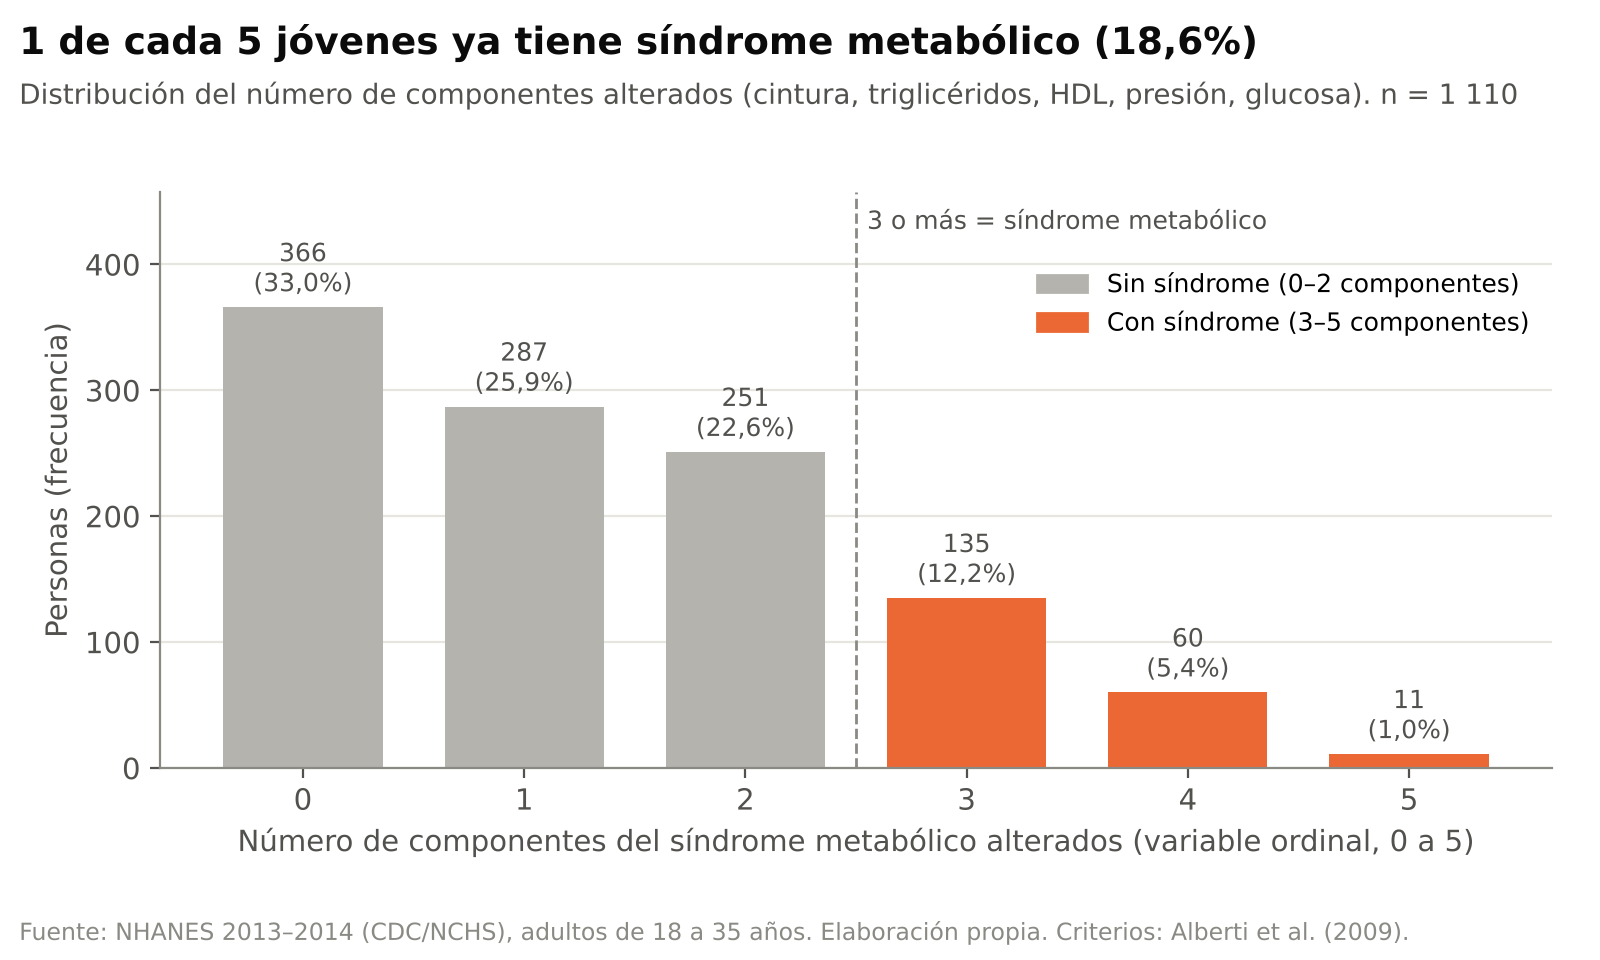

In [9]:
display(Image(filename=str(FIG_A2 / 'fig1_componentes.png'), width=760))

**Figura 2 · Bivariada.** Cintura vs. ácido úrico: correlación positiva moderada (Spearman).

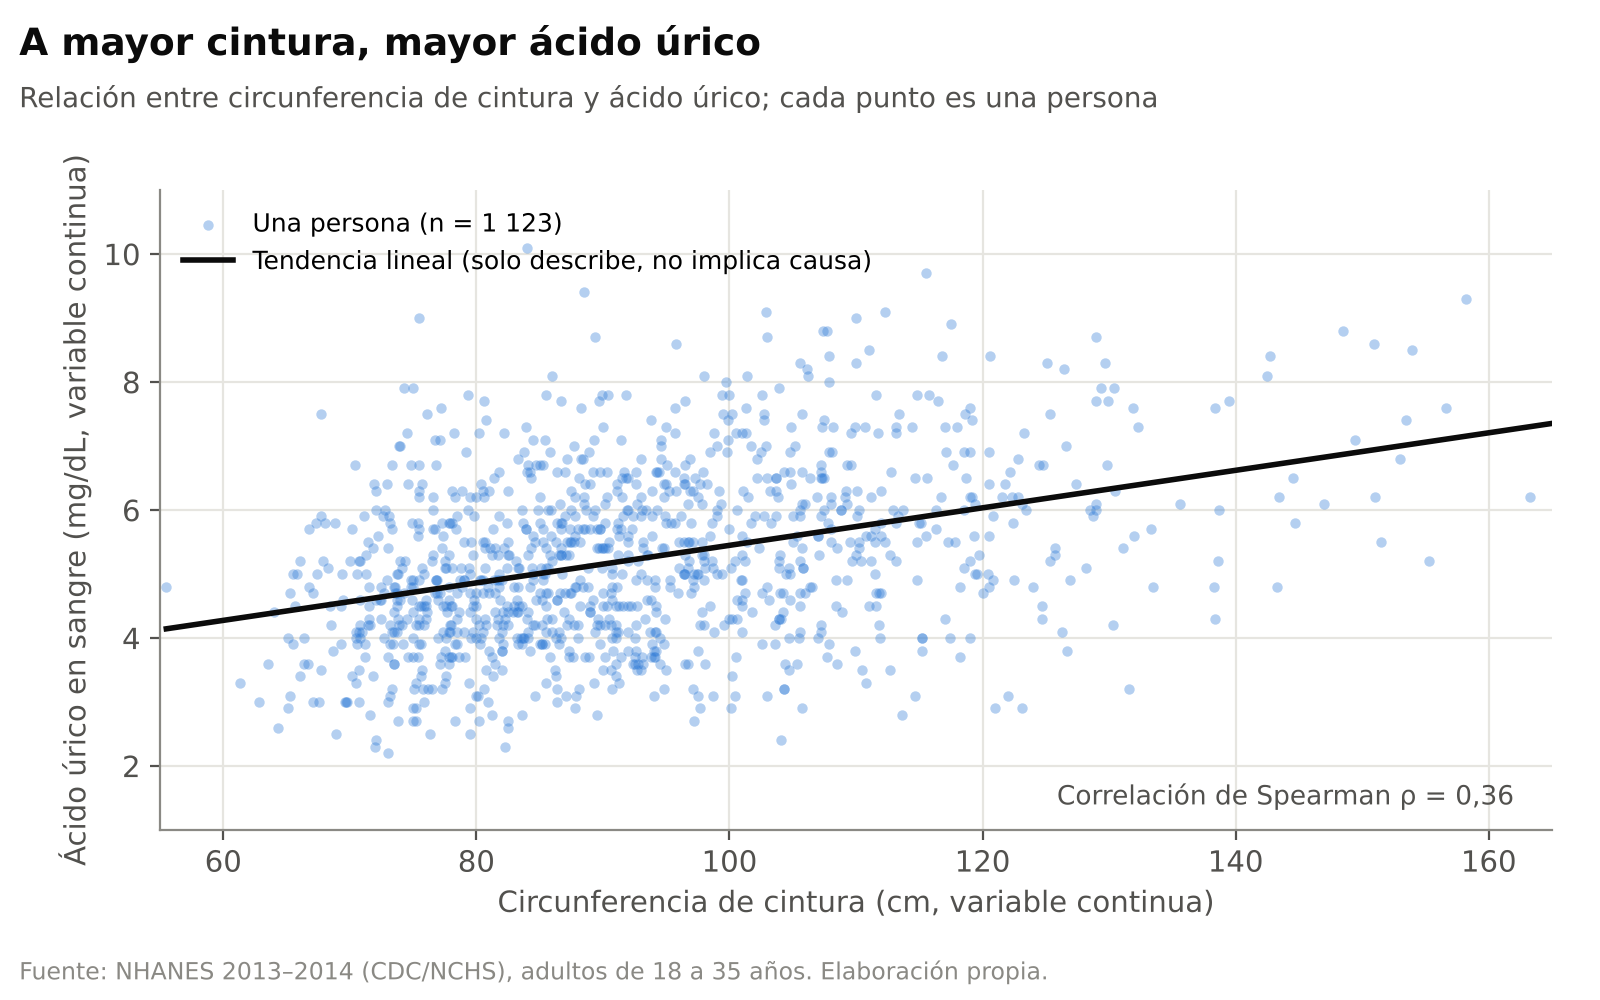

In [10]:
display(Image(filename=str(FIG_A2 / 'fig2_cintura_acido_urico.png'), width=760))

**Figura 3 · Multivariada.** Misma relación separada por sexo y coloreada por síndrome metabólico. Base de la versión interactiva del Avance 3.

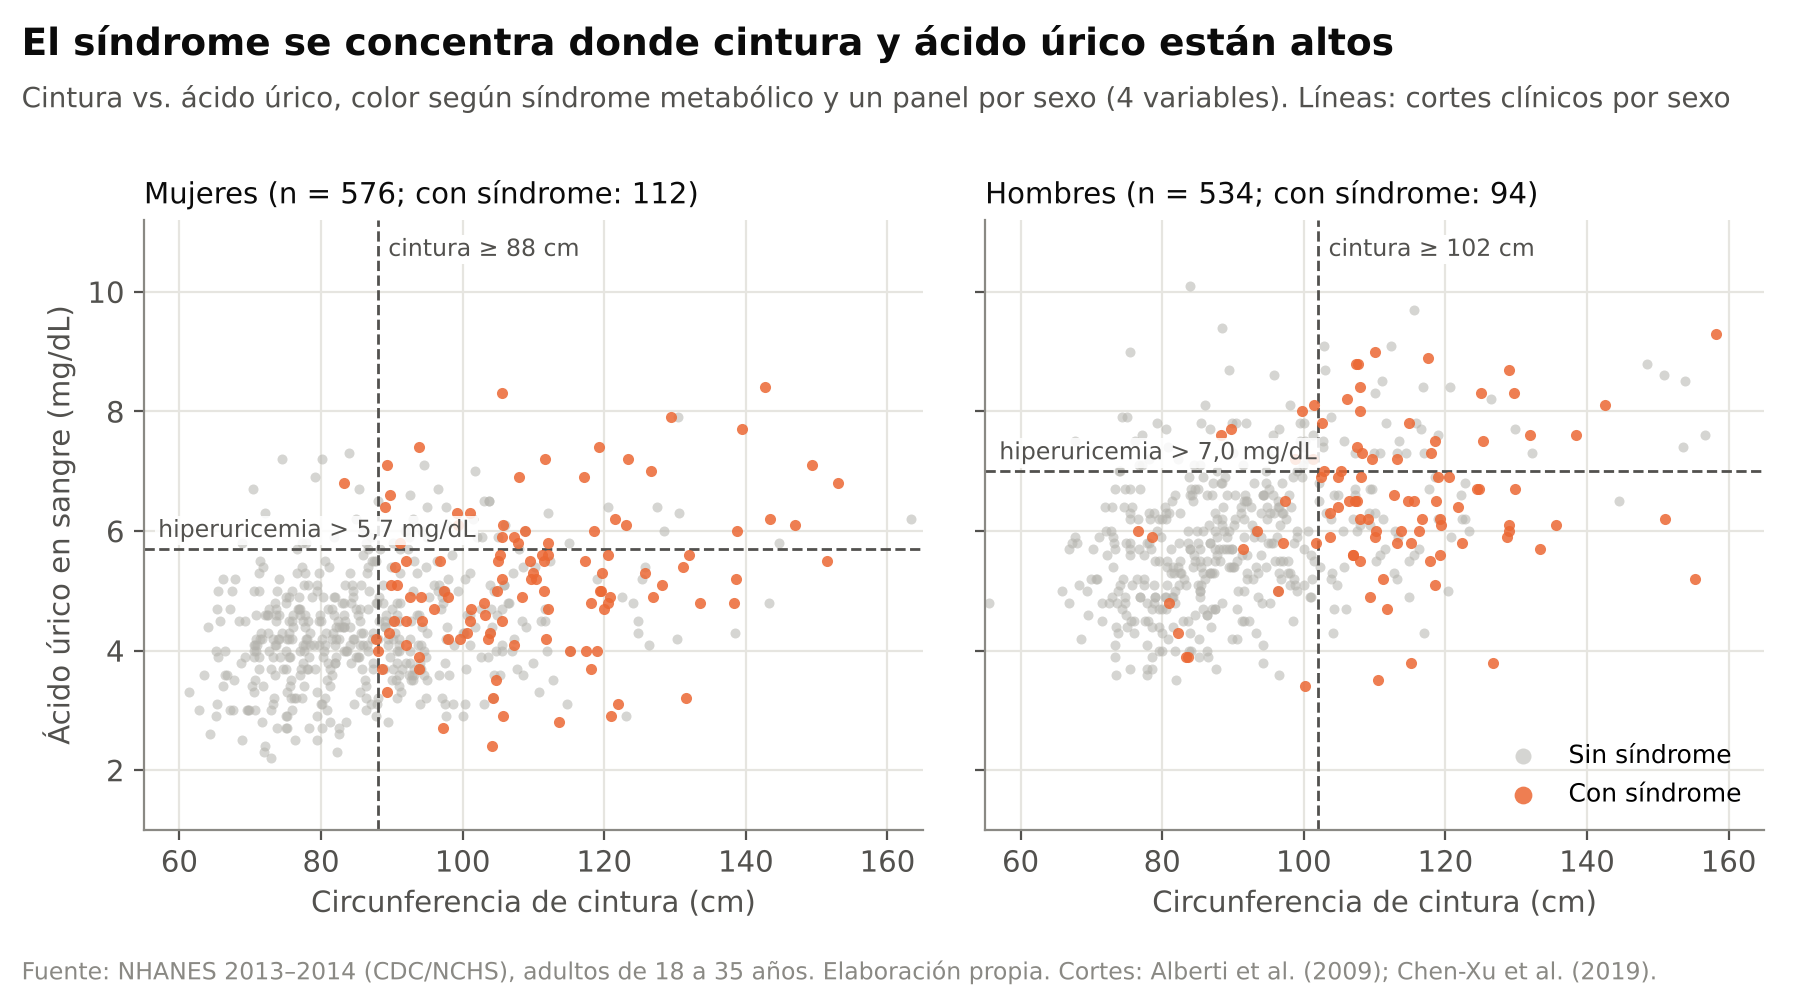

In [11]:
display(Image(filename=str(FIG_A2 / 'fig3_multivariada.png'), width=760))

**Figura 4 · Temporal.** Actividad física promedio por hora del día (acelerómetro), con y sin síndrome.

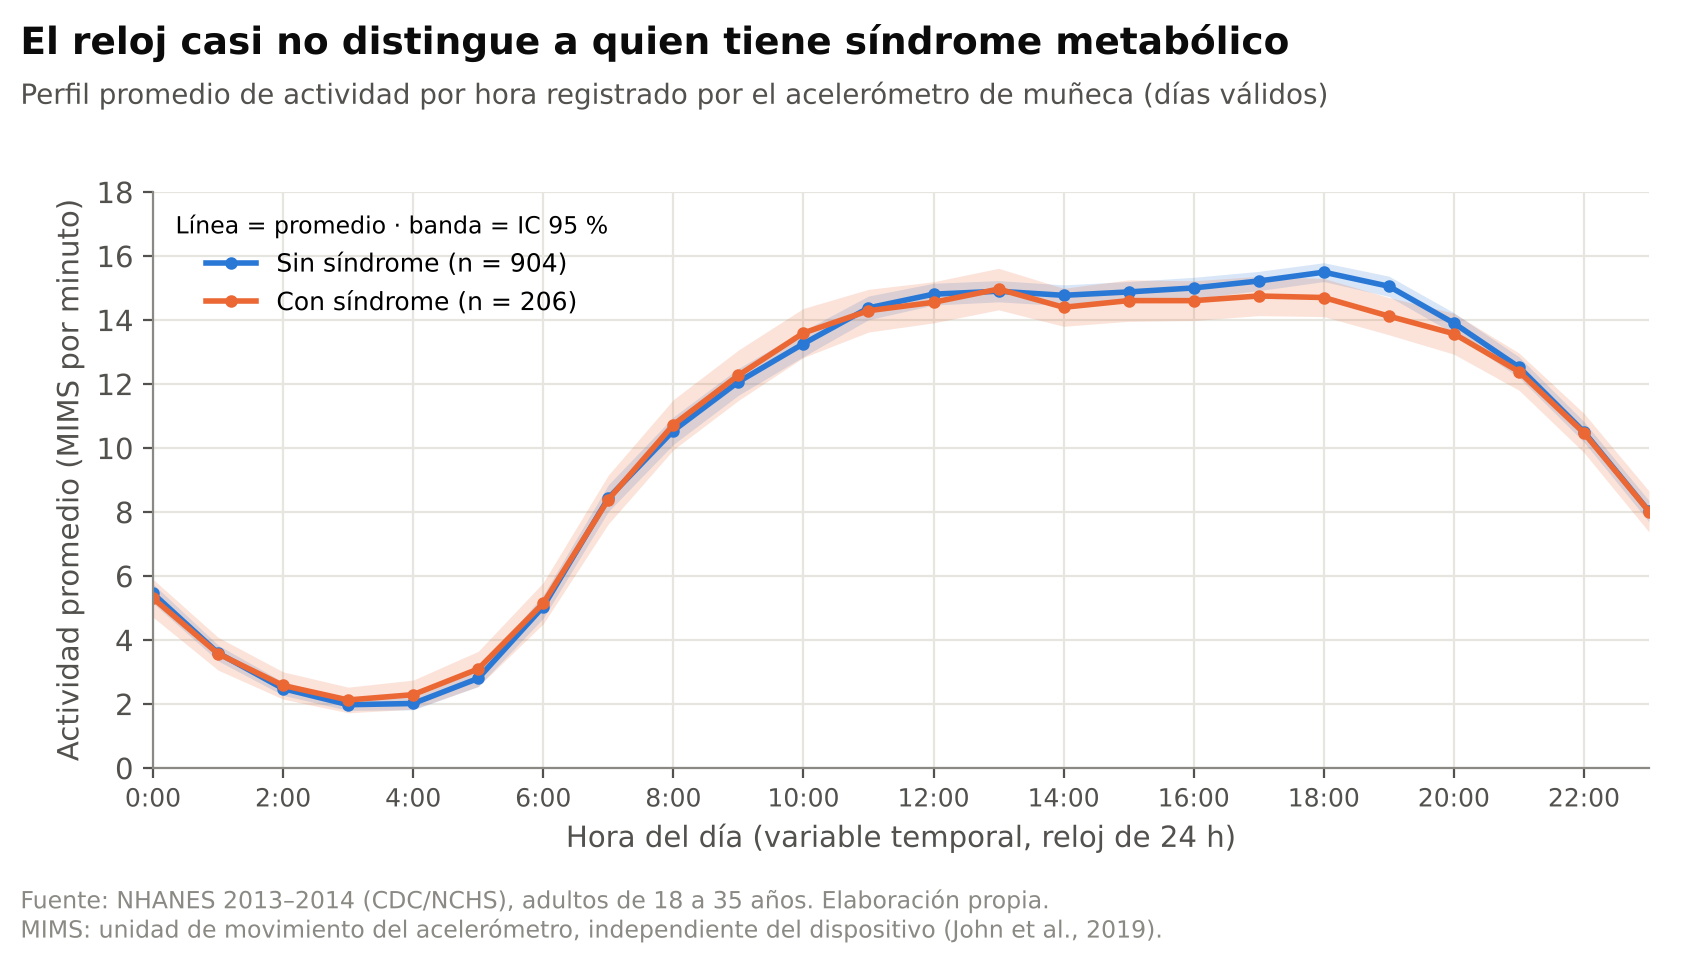

In [12]:
display(Image(filename=str(FIG_A2 / 'fig4_temporal.png'), width=760))

**Figura 5 · Proporciones.** Porcentaje que no lo sabe por componente. Base de la versión estática mejorada del Avance 3.

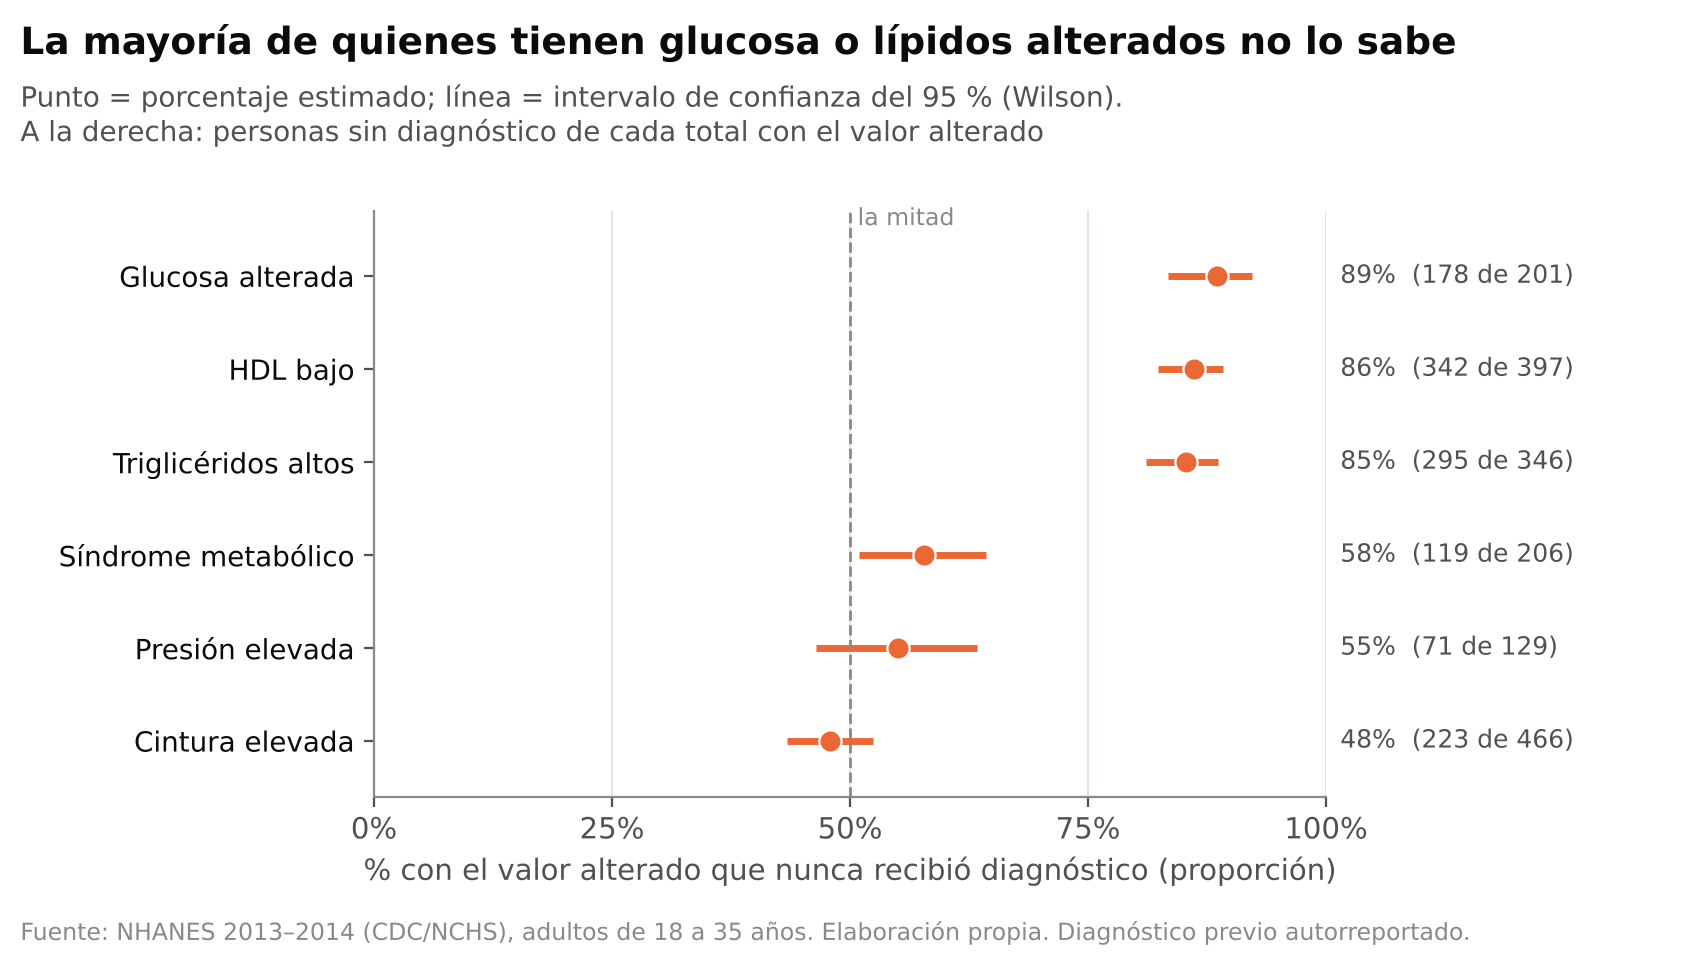

In [13]:
display(Image(filename=str(FIG_A2 / 'fig5_no_lo_sabe.png'), width=760))

## 4. Visualizaciones finales (Avance 3)

### 4.1 Visualización estática mejorada (matplotlib)

Parte de la figura 5. Cambios: el título dice el hallazgo, los componentes se agrupan por **cómo se detectan** (análisis de sangre vs. consulta), el naranja se reserva para lo que requiere análisis de sangre y el gris es contexto, una anotación señala la conclusión, columnas a la derecha con el porcentaje y los casos (k de n), y un pie con fuente, fecha de extracción, tamaño de muestra y método del intervalo.

ok


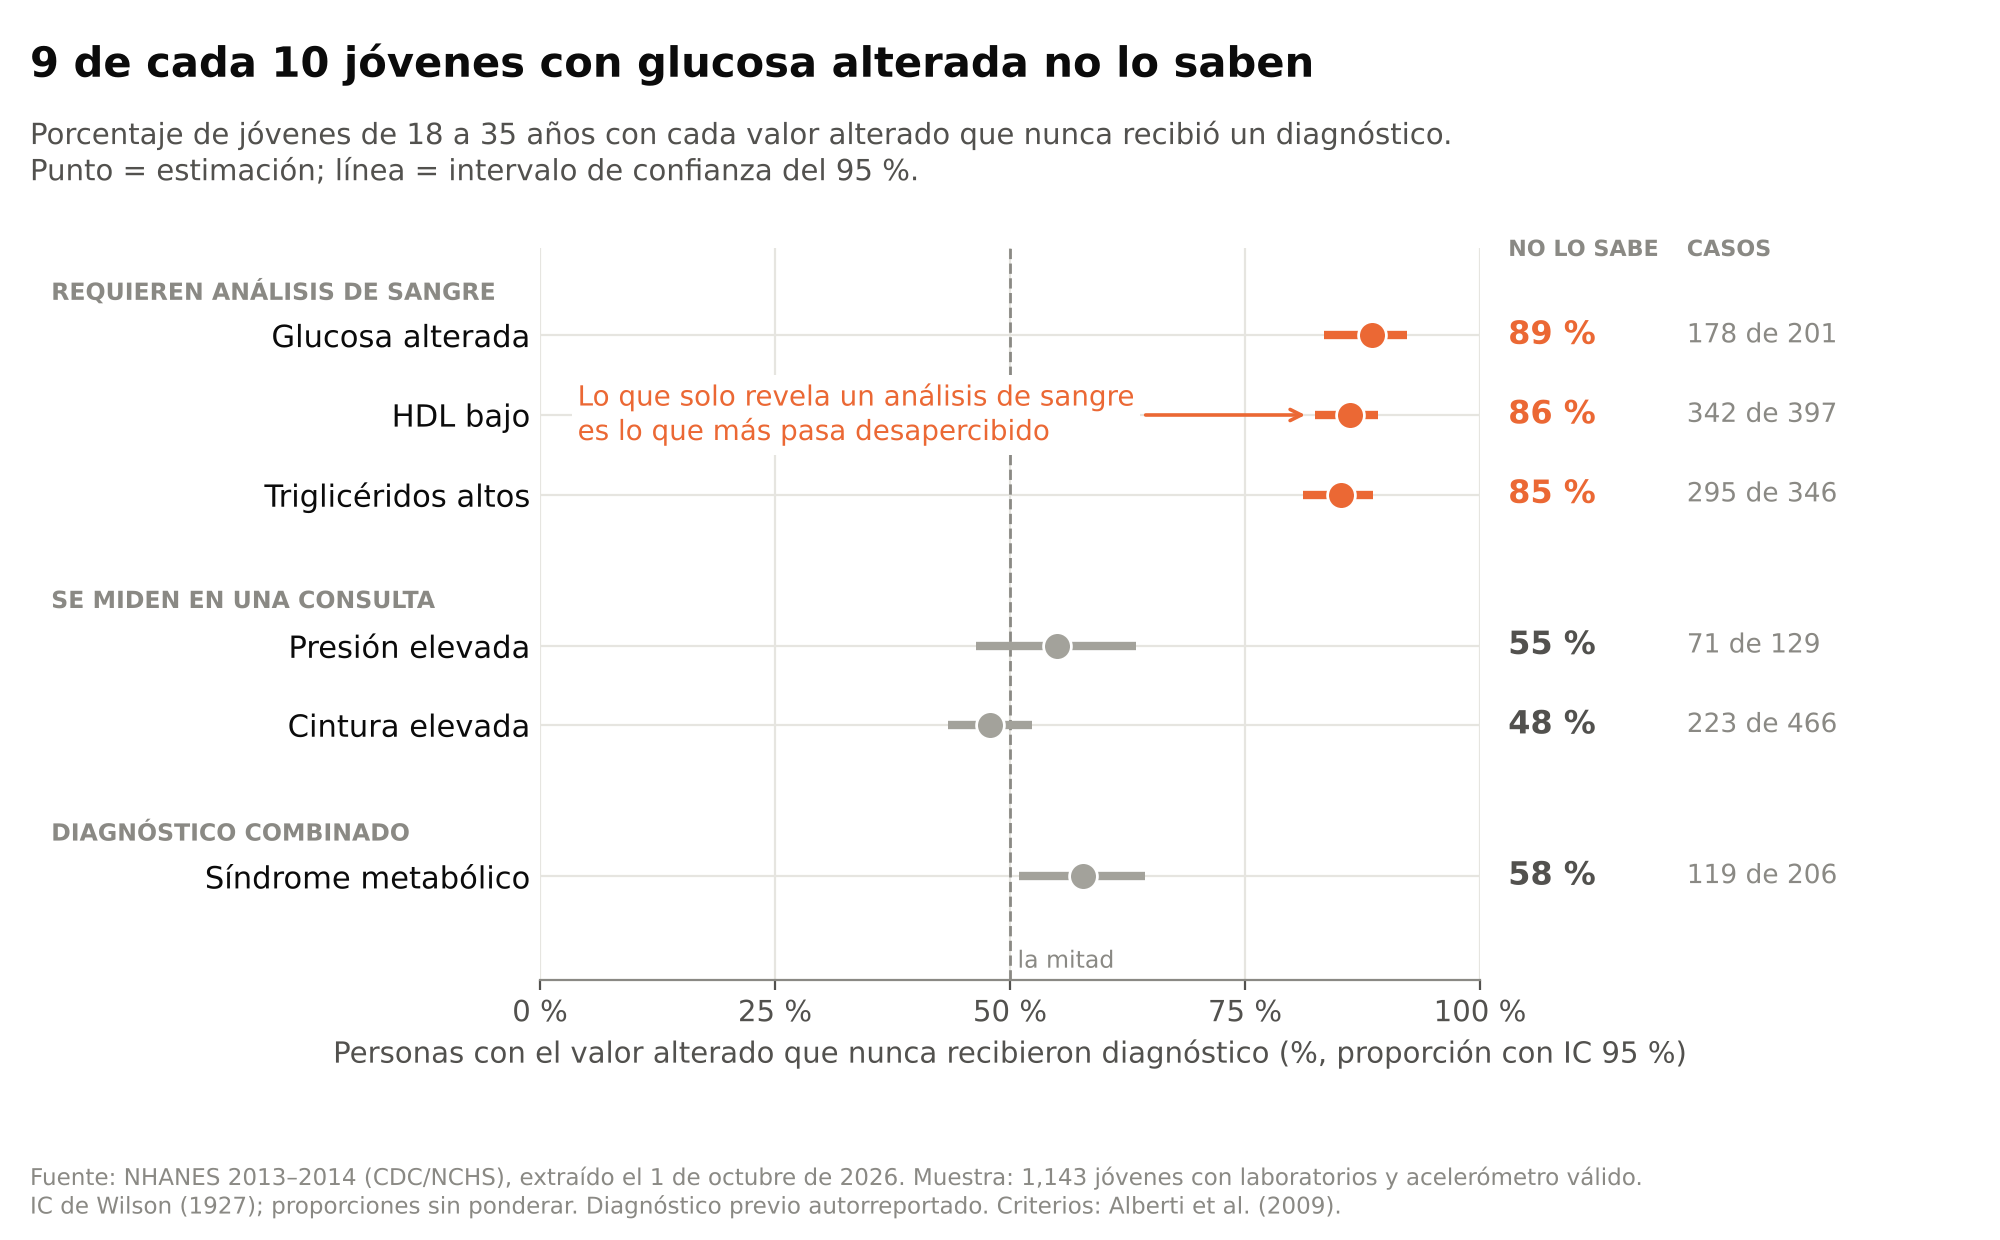

In [14]:
_ = correr('05_estatica_avance3.py')
display(Image(filename=str(FIG_A3 / 'estatica_no_lo_sabe.png'), width=820))

### 4.2 Visualización interactiva (Plotly)

Parte de la figura 3. Se genera un HTML autónomo (`figuras/avance3/interactiva_cintura_acido_urico.html`) que se abre en cualquier navegador sin instalar nada. Cada interacción responde una pregunta:

| Interacción | Pregunta que responde |
|---|---|
| Pasar el cursor sobre un punto | ¿Quién es esta persona? Edad, IMC, cuáles componentes tiene alterados, si tiene hiperuricemia y si sabía que tenía síndrome. |
| Botones por grupo de edad | ¿El patrón aparece desde los 18 años o solo en los mayores? (12.7 % de síndrome en 18–24 frente a 26.8 % en 30–35) |
| Clic en la leyenda | Si dejo solo a quienes tienen síndrome, ¿se agrupan arriba y a la derecha de los cortes clínicos? |
| Zoom y desplazamiento | ¿Qué pasa en la zona de los cortes, donde se amontonan los puntos? |

Al ejecutar el cuaderno en Jupyter la gráfica aparece abajo con toda su interactividad. En GitHub no se dibuja dentro del cuaderno: se consulta en el enlace de GitHub Pages o abriendo el archivo HTML.

**Gráfica interactiva en línea:** [https://ericknobody.github.io/nhanes-sindrome-metabolico-jovenes/figuras/avance3/interactiva_cintura_acido_urico.html](https://ericknobody.github.io/nhanes-sindrome-metabolico-jovenes/figuras/avance3/interactiva_cintura_acido_urico.html)

In [15]:
g = correr('06_interactiva_avance3.py')
g['fig'].show(renderer='notebook_connected', config={'displaylogo': False})

ok 1110 personas, 12 trazas


### 4.3 Componente de inteligencia de negocios (Tableau Public)

`07_datos_tableau.py` prepara un Excel con dos hojas que Tableau relaciona por `ID`: **personas** (una fila por joven, con etiquetas en español e indicadores 1/0) y **componentes** (una fila por componente alterado). Los indicadores quedan vacíos cuando no aplican, de modo que el promedio en Tableau da el mismo porcentaje y denominador que el EDA.

Los valores que imprime la celda siguiente son los que debe mostrar el tablero sin filtros (validación antes de publicar).

In [16]:
_ = correr('07_datos_tableau.py')

Jóvenes: 1143
% síndrome: 18.6% (n = 1110)
% con síndrome que no lo sabe: 57.8% (n = 206)
% hiperuricemia: 16.5%
                           sum  count   mean
Orden Componente                            
1     Glucosa alterada     178    201  0.886
2     HDL bajo             342    397  0.861
3     Triglicéridos altos  295    346  0.853
4     Presión elevada       71    129  0.550
5     Cintura elevada      223    466  0.479
{0.0: 366, 1.0: 287, 2.0: 251, 3.0: 135, 4.0: 60, 5.0: 11}


**Tablero publicado:** [https://public.tableau.com/app/profile/erick.israel.rodriguez.zavala/viz/SindromemetabolicosilenciosojovenesNHANES_/Dashboard1](https://public.tableau.com/app/profile/erick.israel.rodriguez.zavala/viz/SindromemetabolicosilenciosojovenesNHANES_/Dashboard1)

### 4.4 Dashboard final (Avance 4)

`08_dashboard_final.py` integra en una sola página lo más relevante del proyecto, ordenado por jerarquía:

1. **Título con el hallazgo e indicadores grandes** (prevalencia de síndrome y porcentaje que no lo sabe, con IC 95 %).
2. **Gráfica principal:** qué se les escapa, por componente, con intervalos de confianza.
3. **Gráficas de apoyo:** por qué no lo saben (nunca se han medido el colesterol, sin lugar habitual de atención, se perciben sanos) y dónde se concentra (edad).

Los filtros (sexo y categoría de IMC) cambian entre 12 estados que el script calcula por adelantado; con pocos casos, los títulos lo advierten en lugar de afirmar un hallazgo. La celda imprime las cifras sin filtro, que deben coincidir con las de los pasos 2 y 7.

**Dashboard final en línea:** [https://ericknobody.github.io/nhanes-sindrome-metabolico-jovenes/](https://ericknobody.github.io/nhanes-sindrome-metabolico-jovenes/)

In [17]:
_ = correr('08_dashboard_final.py')

Síndrome: 18.6 % | no lo sabe: 57.8 % | hiperuricemia: 16.5 %
No lo sabe por componente: {'Glucosa alterada': '178/201', 'HDL bajo': '342/397', 'Triglicéridos altos': '295/346', 'Presión elevada': '71/129', 'Cintura elevada': '223/466'}
ok: figuras/avance4/dashboard_final.html · 12 estados de filtro


## 5. Limitaciones

- Proporciones **sin ponderar**: describen la muestra, no a la población de EE. UU.
- Diagnóstico previo **autorreportado**: «no lo sabe» puede incluir a quien lo olvidó o no lo entendió.
- Glucosa en ayunas solo en una submuestra; en el resto se usa HbA1c ≥ 5.7 % como sustituto.
- Diseño transversal: las relaciones son asociaciones, no causas.
- Datos de 2013–2014 (último ciclo con acelerómetro de 24 h y laboratorios en la misma muestra).

## 6. Referencias

- Alberti, K. G. M. M., Eckel, R. H., Grundy, S. M., Zimmet, P. Z., Cleeman, J. I., Donato, K. A., … Smith, S. C. (2009). Harmonizing the metabolic syndrome. *Circulation, 120*(16), 1640–1645. https://doi.org/10.1161/CIRCULATIONAHA.109.192644
- American Diabetes Association. (2024). 2. Diagnosis and classification of diabetes: Standards of Care in Diabetes—2024. *Diabetes Care, 47*(Suppl. 1), S20–S42. https://doi.org/10.2337/dc24-S002
- Centers for Disease Control and Prevention. (2024). *Adult BMI categories*. https://www.cdc.gov/bmi/adult-calculator/bmi-categories.html
- Chen-Xu, M., Yokose, C., Rai, S. K., Pillinger, M. H., & Choi, H. K. (2019). Contemporary prevalence of gout and hyperuricemia in the United States and decadal trends: The National Health and Nutrition Examination Survey, 2007–2016. *Arthritis & Rheumatology, 71*(6), 991–999. https://doi.org/10.1002/art.40807
- National Center for Health Statistics. (s. f.). *National Health and Nutrition Examination Survey 2013–2014*. Centers for Disease Control and Prevention. Recuperado el 1 de octubre de 2026, de https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?BeginYear=2013
- Troiano, R. P., Berrigan, D., Dodd, K. W., Mâsse, L. C., Tilert, T., & McDowell, M. (2008). Physical activity in the United States measured by accelerometer. *Medicine & Science in Sports & Exercise, 40*(1), 181–188. https://doi.org/10.1249/mss.0b013e31815a51b3
- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953